<a href="https://colab.research.google.com/github/honggi82/Software_application_lecture/blob/main/Transformer_Traffic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 라이브러리 가져오기

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras.utils import get_file
from keras.models import Sequential
from keras.layers import Layer, Dense, Flatten
from keras.layers import MultiHeadAttention, LayerNormalization
from keras_hub.layers import PositionEmbedding

# 데이터셋 다운로드

In [2]:
# PeMSD7 data
url = 'https://github.com/VeritasYin/STGCN_IJCAI-18/raw/master/dataset/PeMSD7_Full.zip'
data_dir = get_file(origin=url, extract=True)
speeds = pd.read_csv(os.path.join(data_dir, 'PeMSD7_V_228.csv'), header=None).to_numpy()
print(speeds.shape)

(12672, 228)


# Training, Test 데이터셋 준비

In [3]:
speed = speeds[:, 0] / speeds[:, 0].max()

T = 12
X = []
Y = []
for i in range(len(speed) - T):
  X.append(speed[i:i+T]) # 입력: i ~ i+11번째 값 12개
  Y.append(speed[i+T]) # 정답: i+12번째 값 1개
X = np.array(X).reshape(-1, T, 1) # (12660, 12, 1)
Y = np.array(Y) # (12660,)

n = int(len(X) * 0.8)
train_X = X[:n]
test_X = X[n:]
train_Y = Y[:n]
test_Y = Y[n:]
print(train_X.shape, train_Y.shape, test_X.shape, test_Y.shape)

(10128, 12, 1) (10128,) (2532, 12, 1) (2532,)


# 모델 생성

In [4]:
# Model
class TransformerBlock(Layer):
  def __init__(self, dim, heads):
    super().__init__()
    self.att = MultiHeadAttention(num_heads=heads, key_dim=dim)
    self.ffn = Dense(dim, activation='relu')
    self.norm1 = LayerNormalization()
    self.norm2 = LayerNormalization()
  def call(self, x):
    x = self.norm1(x + self.att(x, x))
    return self.norm2(x + self.ffn(x))
class AddPositionEmbedding(PositionEmbedding):
  def call(self, x):
    return x + super().call(x)

model = Sequential([ Dense(64, input_shape=(12, 1)), AddPositionEmbedding(sequence_length=12),  # Attention 전에 위치 정보 추가
                    TransformerBlock(64, 4), Flatten(), Dense(1)])
model.compile(loss='mse', optimizer='adam')
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12, 64)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding          │ (None, 12, 64)         │           768 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 12, 64)         │        70,784 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 72,449 (283.00 KB)

 Trainable params: 72,449 (283.00 KB)

 Non-trainable params: 0 (0.00 B)

# Training

In [5]:
model.fit(train_X, train_Y, epochs=20, batch_size=64, validation_data=(test_X, test_Y))

Epoch 1/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - loss: 0.0953 - val_loss: 0.0106
Epoch 2/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0054 - val_loss: 0.0058
Epoch 3/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0035 - val_loss: 0.0040
Epoch 4/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0023 - val_loss: 0.0024
Epoch 5/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - val_loss: 0.0026
Epoch 6/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0020 - val_loss: 0.0025
Epoch 7/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - val_loss: 0.0021
Epoch 8/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0016 - val_loss: 0.0022
Epoch 9/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 10/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - val_loss: 0.0022
Epoch 11/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 12/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/st

# Test

80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0017
Test Loss:  0.0017347682733088732
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


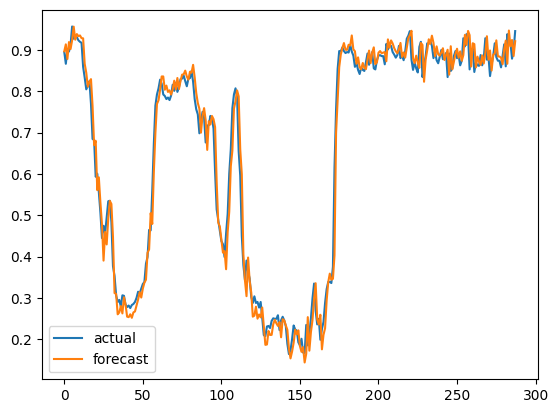

In [6]:
loss = model.evaluate(test_X, test_Y)
print('Test Loss: ', loss)
pred_Y = model.predict(test_X)
plt.plot(test_Y[:288], label='actual')
plt.plot(pred_Y[:288], label='forecast')
plt.legend()
plt.show()